In [1]:

# ARTI 502 - Deep Learning Final Project
# Topic 1: Chest X-ray Pneumonia Identification
# Member 1: Dataset Preparation and EDA

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

# Set reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_PATH = Path("/content/NIH_ChestXray14")
DATA_PATH.mkdir(parents=True, exist_ok=True)

print("Environment initialized successfully!")
print("PyTorch version:", torch.__version__)
print("Working directory:", DATA_PATH)


Environment initialized successfully!
PyTorch version: 2.14.1+cpu
Working directory: /content/NIH_ChestXray14


In [2]:

# Download NIH ChestX-ray14 Metadata

import urllib.request

metadata_url = (
    "https://raw.githubusercontent.com/"
    "gregwchase/nih-chest-xray/master/"
    "data/Data_Entry_2017.csv"
)

csv_path = DATA_PATH / "Data_Entry_2017.csv"

try:
    urllib.request.urlretrieve(
        metadata_url,
        str(csv_path)
    )

    df = pd.read_csv(csv_path)

    required_columns = [
        "Image Index",
        "Finding Labels",
        "Patient ID"
    ]

    missing = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Required columns missing: {missing}"
        )

    print("Metadata loaded successfully!")
    print("Dataset shape:", df.shape)
    print("Total images:", len(df))
    print("Unique patients:", df["Patient ID"].nunique())

    display(df.head())

except Exception as e:
    print("Metadata download/loading failed:", e)
    print("Download the official NIH CSV manually if needed.")


Metadata loaded successfully!
Dataset shape: (112120, 12)
Total images: 112120
Unique patients: 30805


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,058Y,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,058Y,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,058Y,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,081Y,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,081Y,F,PA,2582,2991,0.143,0.143,NaN


In [3]:

# Inspect Pneumonia and No Finding Labels

df["Pneumonia"] = df["Finding Labels"].fillna("").apply(
    lambda x: int("Pneumonia" in x.split("|"))
)

df["No Finding"] = df["Finding Labels"].fillna("").apply(
    lambda x: int("No Finding" in x.split("|"))
)

df["Other Findings"] = (
    (df["Pneumonia"] == 0) &
    (df["No Finding"] == 0)
).astype(int)

print("Pneumonia-labeled images:",
      df["Pneumonia"].sum())

print("No Finding images:",
      df["No Finding"].sum())

print("Other findings without Pneumonia:",
      df["Other Findings"].sum())

print("\nPneumonia prevalence:")
print(f"{100 * df['Pneumonia'].mean():.2f}%")

print("\nMissing values:")
print(df[["Image Index", "Finding Labels", "Patient ID"]]
      .isna().sum())

print("\nDuplicate image filenames:",
      df["Image Index"].duplicated().sum())


Pneumonia-labeled images: 1353
No Finding images: 60412
Other findings without Pneumonia: 50355

Pneumonia prevalence:
1.21%

Missing values:
Image Index       0
Finding Labels    0
Patient ID        0
dtype: int64

Duplicate image filenames: 0


In [4]:

# Step 4: Dataset Cleaning and Statistical Analysis

# Remove fully empty columns
df = df.dropna(axis=1, how="all").copy()

# Convert patient ages from strings such as "058Y"
df["Age_Years"] = pd.to_numeric(
    df["Patient Age"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Basic dataset statistics
print("Dataset dimensions:", df.shape)
print("Total unique patients:", df["Patient ID"].nunique())
print("Duplicate rows:", df.duplicated().sum())
print("Missing ages:", df["Age_Years"].isna().sum())

print("\nAge statistics:")
display(df["Age_Years"].describe())

print("\nGender distribution:")
display(df["Patient Gender"].value_counts())

print("\nView position distribution:")
display(df["View Position"].value_counts())

print("\nPatient image counts:")
display(df.groupby("Patient ID").size().describe())

print("\nUnusual ages above 100:")
print((df["Age_Years"] > 100).sum())


Dataset dimensions: (112120, 15)
Total unique patients: 30805
Duplicate rows: 0
Missing ages: 0

Age statistics:


,Age_Years
count,112120.000000
mean,46.901463
std,16.839923
min,1.000000
25%,35.000000
50%,49.000000
75%,59.000000
max,414.000000



Gender distribution:


,count
Patient Gender,
M,63340
F,48780



View position distribution:


,count
View Position,
PA,67310
AP,44810



Patient image counts:


,0
count,30805.000000
mean,3.639669
std,7.266734
min,1.000000
25%,1.000000
50%,1.000000
75%,3.000000
max,184.000000



Unusual ages above 100:
16


Finding label frequencies:


,Image Count
No Finding,60412
Infiltration,19870
Effusion,13307
Atelectasis,11535
Nodule,6323
Mass,5746
Pneumothorax,5298
Consolidation,4667
Pleural_Thickening,3385
Cardiomegaly,2772


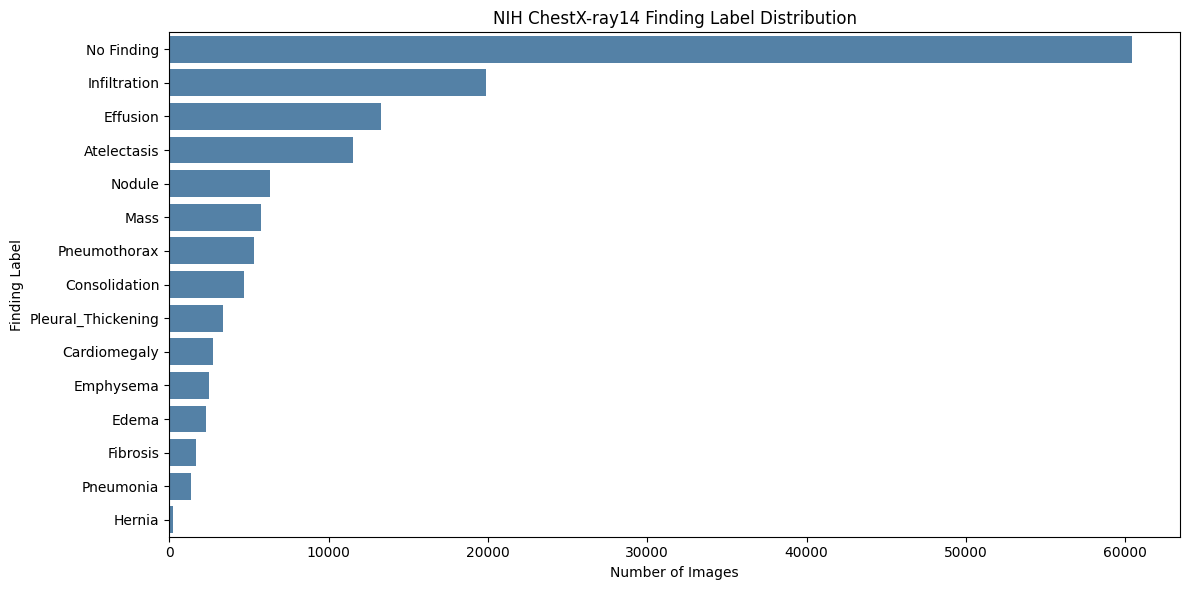

In [5]:

# Step 5: Analyze All ChestX-ray14 Labels

from collections import Counter

all_labels = []

for labels in df["Finding Labels"]:
    all_labels.extend(labels.split("|"))

label_counts = pd.Series(
    Counter(all_labels)
).sort_values(ascending=False)

print("Finding label frequencies:")
display(label_counts.to_frame("Image Count"))

plt.figure(figsize=(12, 6))

sns.barplot(
    x=label_counts.values,
    y=label_counts.index,
    color="steelblue"
)

plt.title("NIH ChestX-ray14 Finding Label Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Finding Label")
plt.tight_layout()
plt.show()


Pneumonia images: 1353
Patients with pneumonia-labeled images: 955

Pneumonia label counts by gender:


,count
Patient Gender,
M,790
F,563



Pneumonia label counts by view position:


,count
View Position,
AP,759
PA,594


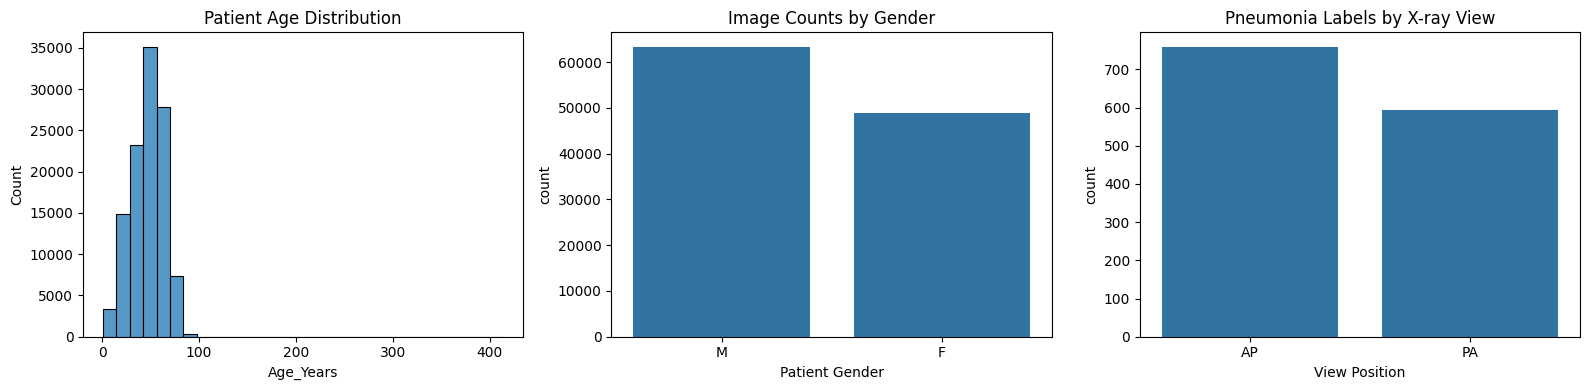

In [6]:

# Step 6: Pneumonia Subgroup Analysis

pneumonia_df = df[df["Pneumonia"] == 1].copy()

print("Pneumonia images:", len(pneumonia_df))
print("Patients with pneumonia-labeled images:",
      pneumonia_df["Patient ID"].nunique())

print("\nPneumonia label counts by gender:")
display(pneumonia_df["Patient Gender"].value_counts())

print("\nPneumonia label counts by view position:")
display(pneumonia_df["View Position"].value_counts())

# Show distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(
    data=df,
    x="Age_Years",
    bins=30,
    ax=axes[0]
)
axes[0].set_title("Patient Age Distribution")

sns.countplot(
    data=df,
    x="Patient Gender",
    ax=axes[1]
)
axes[1].set_title("Image Counts by Gender")

sns.countplot(
    data=pneumonia_df,
    x="View Position",
    ax=axes[2]
)
axes[2].set_title("Pneumonia Labels by X-ray View")

plt.tight_layout()
plt.show()


In [7]:

# Step 7: Patient-Level Train / Validation / Test Split

from sklearn.model_selection import train_test_split

# Patient-level labels: positive if any image has Pneumonia
patient_labels = (
    df.groupby("Patient ID")["Pneumonia"]
    .max()
    .reset_index()
)

# First split: 70% train, 30% remaining
train_patients, remaining_patients = train_test_split(
    patient_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=patient_labels["Pneumonia"]
)

# Second split: half validation, half testing
val_patients, test_patients = train_test_split(
    remaining_patients,
    test_size=0.50,
    random_state=SEED,
    stratify=remaining_patients["Pneumonia"]
)

train_ids = set(train_patients["Patient ID"])
val_ids = set(val_patients["Patient ID"])
test_ids = set(test_patients["Patient ID"])

# Assign each image to its patient-level split
def assign_split(patient_id):
    if patient_id in train_ids:
        return "train"
    elif patient_id in val_ids:
        return "validation"
    elif patient_id in test_ids:
        return "test"
    else:
        raise ValueError("Unassigned patient ID")

df["Split"] = df["Patient ID"].apply(assign_split)

# Verify no overlapping patients
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("Patient-level split completed successfully!")

summary = df.groupby("Split").agg(
    Images=("Image Index", "count"),
    Patients=("Patient ID", "nunique"),
    Pneumonia_Images=("Pneumonia", "sum")
)

summary["Pneumonia_Rate_%"] = (
    summary["Pneumonia_Images"] / summary["Images"] * 100
).round(2)

display(summary)


Patient-level split completed successfully!


,Images,Patients,Pneumonia_Images,Pneumonia_Rate_%
Split,,,,
test,16374,4621,193,1.18
train,78921,21563,952,1.21
validation,16825,4621,208,1.24


In [8]:

# Step 8: Export Cleaned Metadata and Dataset Splits

output_path = DATA_PATH / "outputs"
output_path.mkdir(parents=True, exist_ok=True)

df.to_csv(
    output_path / "NIH_ChestXray14_Metadata_Cleaned.csv",
    index=False
)

for split_name in ["train", "validation", "test"]:
    df[df["Split"] == split_name].to_csv(
        output_path / f"{split_name}_metadata.csv",
        index=False
    )

label_counts.to_csv(
    output_path / "label_frequencies.csv",
    header=["Image Count"]
)

summary.to_csv(
    output_path / "split_summary.csv"
)

print("Files exported successfully!")
print("\nOutput directory:", output_path)

for file in output_path.iterdir():
    print("-", file.name)


Files exported successfully!

Output directory: /content/NIH_ChestXray14/outputs
- train_metadata.csv
- split_summary.csv
- test_metadata.csv
- validation_metadata.csv
- label_frequencies.csv
- NIH_ChestXray14_Metadata_Cleaned.csv


In [9]:

# Step 9: Flag Invalid Patient Ages

df["Age_Years_Clean"] = df["Age_Years"].where(
    df["Age_Years"].between(0, 100),
    np.nan
)

invalid_ages = df.loc[
    df["Age_Years_Clean"].isna(),
    ["Image Index", "Patient ID", "Patient Age", "Age_Years"]
]

print("Records with invalid or missing age:",
      len(invalid_ages))

display(invalid_ages.head(20))

print("\nCleaned age statistics:")
display(df["Age_Years_Clean"].describe())


Records with invalid or missing age: 16


,Image Index,Patient ID,Patient Age,Age_Years
20852,00005567_000.png,5567,412Y,412
46965,00011973_002.png,11973,414Y,414
48284,00012238_010.png,12238,148Y,148
55742,00013950_000.png,13950,148Y,148
58650,00014520_026.png,14520,150Y,150
62929,00015558_000.png,15558,149Y,149
74884,00018366_044.png,18366,152Y,152
78795,00019346_000.png,19346,151Y,151
84810,00020900_002.png,20900,411Y,411
85404,00021047_002.png,21047,412Y,412



Cleaned age statistics:


,Age_Years_Clean
count,112104.000000
mean,46.872574
std,16.598152
min,1.000000
25%,35.000000
50%,49.000000
75%,59.000000
max,95.000000


In [10]:

# Step 10: Image Preprocessing for CNNs

from torchvision import transforms

IMAGE_SIZE = 224

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

print("Training and evaluation transforms ready!")
print("Image size:", IMAGE_SIZE)


Training and evaluation transforms ready!
Image size: 224


In [11]:

# Step 11: Reusable NIH Chest X-ray Dataset Class

from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pathlib import Path

class NIHChestXrayDataset(Dataset):

    def __init__(self, metadata, image_lookup, transform=None):
        self.metadata = metadata.reset_index(drop=True)
        self.image_lookup = image_lookup
        self.transform = transform

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, idx):
        row = self.metadata.iloc[idx]

        filename = row["Image Index"]
        image_path = self.image_lookup[filename]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            float(row["Pneumonia"]),
            dtype=torch.float32
        )

        return image, label


def build_image_lookup(image_directory):
    image_directory = Path(image_directory)

    return {
        path.name: str(path)
        for path in image_directory.rglob("*.png")
    }


def create_data_loader(metadata, image_lookup,
                       transform, batch_size=32,
                       shuffle=False):

    available_metadata = metadata[
        metadata["Image Index"].isin(image_lookup)
    ].copy()

    dataset = NIHChestXrayDataset(
        metadata=available_metadata,
        image_lookup=image_lookup,
        transform=transform
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=2
    )


print("Reusable NIH Dataset and DataLoader functions defined!")


Reusable NIH Dataset and DataLoader functions defined!


In [12]:

# Step 12: Save All Dataset Preparation Deliverables

import json
import shutil
from google.colab import files

output_path = DATA_PATH / "outputs"
output_path.mkdir(parents=True, exist_ok=True)

# Save final cleaned metadata and splits
df.to_csv(output_path / "metadata_cleaned.csv", index=False)

for split_name in ["train", "validation", "test"]:
    df[df["Split"] == split_name].to_csv(
        output_path / f"{split_name}_metadata.csv",
        index=False
    )

# Save descriptive statistics
df["Age_Years_Clean"].describe().to_csv(
    output_path / "age_statistics.csv"
)

label_counts.to_csv(
    output_path / "label_frequencies.csv",
    header=["Image Count"]
)

summary.to_csv(output_path / "split_summary.csv")

# Save configuration
config = {
    "dataset": "NIH ChestX-ray14",
    "target": "Pneumonia label present vs absent",
    "seed": SEED,
    "split_method": "Patient-level stratified split",
    "image_size": IMAGE_SIZE,
    "normalization": "ImageNet mean and standard deviation",
    "classes": ["Pneumonia label absent", "Pneumonia label present"]
}

with open(output_path / "dataset_config.json", "w") as f:
    json.dump(config, f, indent=4)

zip_file = shutil.make_archive(
    "/content/NIH_Dataset_Preparation",
    "zip",
    output_path
)

print("Dataset preparation files saved!")
print("ZIP:", zip_file)

files.download(zip_file)


Dataset preparation files saved!
ZIP: /content/NIH_Dataset_Preparation.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

# Step 13: Check Available X-ray Images

from pathlib import Path

image_files = list(DATA_PATH.rglob("*.png"))

print("Available X-ray images:", len(image_files))
print("Expected metadata records:", len(df))

if image_files:
    print("\nExample image files:")
    for path in image_files[:5]:
        print(path)
else:
    print("\nNo X-ray images found yet.")
    print("The metadata is ready, but images still need downloading.")


Available X-ray images: 0
Expected metadata records: 112120

No X-ray images found yet.
The metadata is ready, but images still need downloading.


In [14]:

# Step 14: Verify Exported Dataset Splits

train_df = pd.read_csv(output_path / "train_metadata.csv")
val_df = pd.read_csv(output_path / "validation_metadata.csv")
test_df = pd.read_csv(output_path / "test_metadata.csv")

# Check patient overlap
train_patients = set(train_df["Patient ID"])
val_patients = set(val_df["Patient ID"])
test_patients = set(test_df["Patient ID"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

# Check all records are included exactly once
assert len(train_df) + len(val_df) + len(test_df) == len(df)

print("All dataset splits verified successfully!")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("No patient overlap detected.")


All dataset splits verified successfully!
Training images: 78921
Validation images: 16825
Testing images: 16374
No patient overlap detected.


In [15]:

# Step 15: Discover Public NIH Chest X-ray Images

import subprocess

# Install AWS CLI if necessary
subprocess.run(
    ["pip", "-q", "install", "awscli"],
    check=True
)

bucket = "s3://nih-chest-x-rays"

result = subprocess.run(
    [
        "aws", "s3", "ls", bucket + "/",
        "--no-sign-request",
        "--region", "us-east-2"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nAvailable folders:")
print(result.stdout[:6000])

if result.returncode != 0:
    print("\nAccess error:")
    print(result.stderr[:2000])


Return code: 0

Available folders:
                           PRE images_1024x1024/
                           PRE images_128x128/
                           PRE images_224x224/
                           PRE images_260x260/
                           PRE images_300x300/
                           PRE images_384x384/
                           PRE index.html/
                           PRE qwen/
                           PRE results/
                           PRE scripts/
                           PRE splits/
                           PRE trainium/
2025-10-29 09:13:02        895 index.html



In [16]:

# Step 16: Download Sample NIH Chest X-ray Images

import subprocess
from pathlib import Path

sample_dir = DATA_PATH / "sample_images"
sample_dir.mkdir(parents=True, exist_ok=True)

# Select images from the TRAINING split only
train_sample = df[df["Split"] == "train"]

positive_samples = train_sample[
    train_sample["Pneumonia"] == 1
].sample(n=6, random_state=42)

negative_samples = train_sample[
    train_sample["No Finding"] == 1
].sample(n=6, random_state=42)

sample_metadata = pd.concat(
    [positive_samples, negative_samples],
    ignore_index=True
)

bucket_prefix = "s3://nih-chest-x-rays/images_224x224/"

successful = []
failed = []

for filename in sample_metadata["Image Index"]:

    source = bucket_prefix + filename
    destination = sample_dir / filename

    result = subprocess.run(
        [
            "aws", "s3", "cp",
            source,
            str(destination),
            "--no-sign-request",
            "--region", "us-east-2",
            "--only-show-errors"
        ],
        capture_output=True,
        text=True
    )

    if result.returncode == 0 and destination.is_file():
        successful.append(filename)
    else:
        failed.append(filename)
        print("Failed:", filename, result.stderr[:200])

print("\nSuccessfully downloaded:", len(successful))
print("Failed downloads:", len(failed))
print("Images directory:", sample_dir)

assert len(successful) == 12, (
    "Some images were not downloaded. Check errors above."
)



Successfully downloaded: 12
Failed downloads: 0
Images directory: /content/NIH_ChestXray14/sample_images


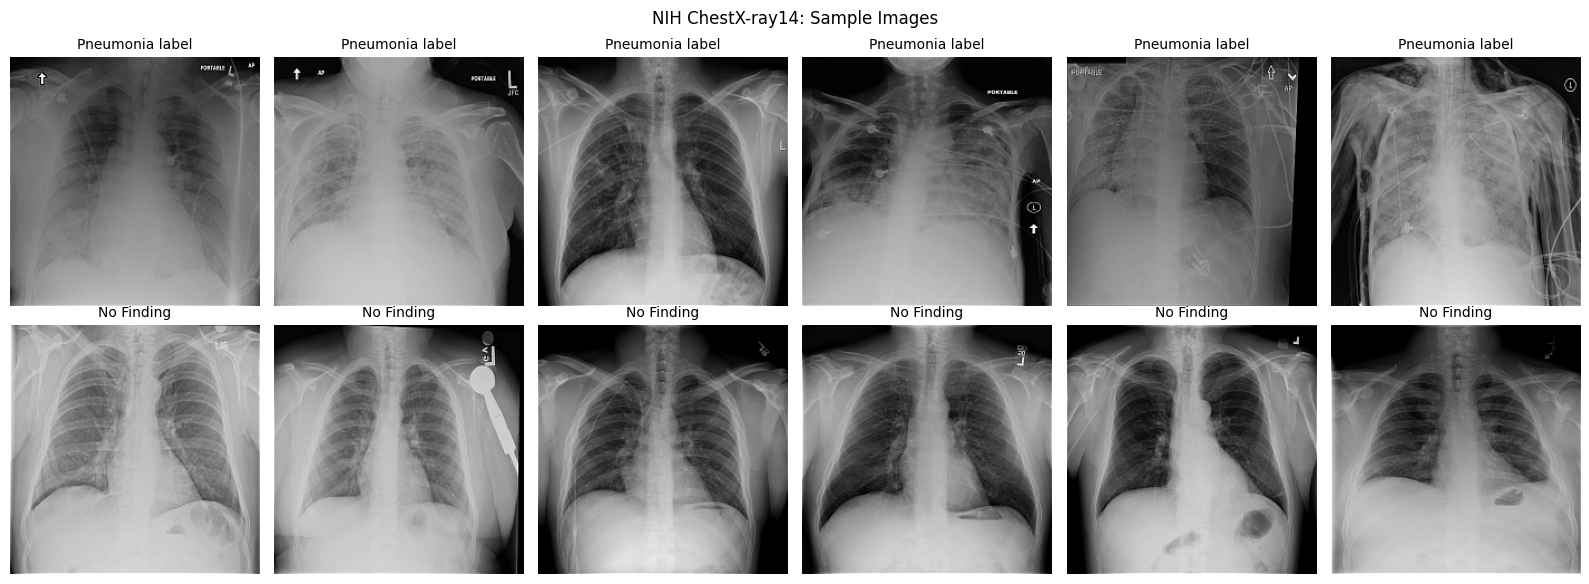

In [17]:

# Step 17: Visualize Real Chest X-ray Images

from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 6, figsize=(16, 6))

for i, row in sample_metadata.iterrows():

    image_path = sample_dir / row["Image Index"]

    with Image.open(image_path) as image:
        image_array = image.convert("L").copy()

    ax = axes[i // 6, i % 6]

    ax.imshow(image_array, cmap="gray")

    label = (
        "Pneumonia label"
        if row["Pneumonia"] == 1
        else "No Finding"
    )

    ax.set_title(label, fontsize=10)
    ax.axis("off")

plt.suptitle("NIH ChestX-ray14: Sample Images")
plt.tight_layout()
plt.show()


In [18]:

# Step 18: Verify PyTorch DataLoader with Real Images

# Create image lookup dictionary
image_lookup = build_image_lookup(sample_dir)

# Create a DataLoader using available sample images
sample_loader = create_data_loader(
    metadata=sample_metadata,
    image_lookup=image_lookup,
    transform=eval_transform,
    batch_size=4,
    shuffle=False
)

images, labels = next(iter(sample_loader))

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image tensor dtype:", images.dtype)
print("Labels:", labels.tolist())

assert images.shape == (4, 3, 224, 224)
assert labels.shape == (4,)

print("\nPyTorch DataLoader verified successfully!")


Image batch shape: torch.Size([4, 3, 224, 224])
Labels shape: torch.Size([4])
Image tensor dtype: torch.float32
Labels: [1.0, 1.0, 1.0, 1.0]

PyTorch DataLoader verified successfully!


In [19]:

# Step 19: Package Dataset Preparation Deliverables

import shutil
from pathlib import Path

handoff_dir = Path("/content/NIH_Dataset_Handoff")
handoff_dir.mkdir(parents=True, exist_ok=True)

# Copy metadata, split files and configuration
for file_path in output_path.iterdir():
    if file_path.is_file():
        shutil.copy2(
            file_path,
            handoff_dir / file_path.name
        )

# Copy the 12 sample images
sample_output_dir = handoff_dir / "sample_images"
sample_output_dir.mkdir(exist_ok=True)

for image_path in sample_dir.glob("*.png"):
    shutil.copy2(
        image_path,
        sample_output_dir / image_path.name
    )

# Save sample labels
sample_metadata.to_csv(
    handoff_dir / "sample_metadata.csv",
    index=False
)

# Create dataset handoff instructions
readme = """NIH ChestX-ray14 - Dataset Preparation
ARTI 502 Deep Learning Final Project

DATASET:
112,120 images from 30,805 patients.

TARGET:
Binary classification: Pneumonia label present vs absent.
A negative label does not necessarily indicate healthy lungs.

SPLITS:
Patient-level train/validation/test split using seed 42.
The same split files must be used by both CNN models.

PREPROCESSING:
Image size: 224 x 224
Image mode: RGB
ImageNet normalization.
Horizontal flip is optional training-only augmentation.

CONTENTS:
- Cleaned metadata
- Train/validation/test metadata CSV files
- Label frequency statistics
- Dataset configuration
- 12 example X-rays with their labels

IMPORTANT:
This package contains only 12 example images.
It is NOT sufficient for full model training.
Download matching images before running the full experiment.

SOURCE:
NIH ChestX-ray14.
Resized sample images accessed from:
s3://nih-chest-x-rays/images_224x224/

IMPLEMENTATION:
Use the companion Google Colab notebook for the
Dataset class, preprocessing and DataLoader functions.
"""

(handoff_dir / "README.txt").write_text(readme)

# Create ZIP archive
zip_path = shutil.make_archive(
    "/content/NIH_Dataset_Handoff",
    "zip",
    handoff_dir
)

print("Handoff package created successfully!")
print("ZIP location:", zip_path)

from google.colab import files
files.download(zip_path)


Handoff package created successfully!
ZIP location: /content/NIH_Dataset_Handoff.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>